# Anomaly Dataset Exploration

This notebook explores the actuator anomaly dataset in three layers:

1. Binary separation between **normal** and **anomalous** behavior.
2. Multiclass separation between the renamed anomaly mechanisms.
3. Feature distributions and representative traces for torque, power, approximate step energy, tracking error, and temperature.

The original labels are remapped to more descriptive names so the plots read closer to the real mechanical behavior.

In [1]:
from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.express as px
import seaborn as sns
from IPython.display import display
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda value: f"{value:,.3f}")
plt.style.use("seaborn-v0_8-whitegrid")
sns.set_theme(context="talk", style="whitegrid")

def locate_data_file() -> Path:
    roots = [Path.cwd(), *list(Path.cwd().parents[:4])]
    relatives = [
        Path("ml/data/anomaly_dataset.csv"),
        Path("starthack26/ml/data/anomaly_dataset.csv"),
    ]
    for root in roots:
        for relative in relatives:
            candidate = (root / relative).resolve()
            if candidate.exists():
                return candidate
    raise FileNotFoundError("Could not locate ml/data/anomaly_dataset.csv from the current working directory.")

DATA_PATH = locate_data_file()
DATA_PATH

PosixPath('/Users/paulruiz/Documents/Starthack/starthack26/ml/data/anomaly_dataset.csv')

## Load, rename, and enrich the dataset

Renaming used in this notebook:

- `normal` -> **Normal Operation**
- `stabbing` -> **Valve Destabilization (Repeated Poking)**
- `bottle_stuck` -> **Closure Blockage (Bottle Held Open)**
- `gear_stuck` -> **Gear Jam / Transmission Lock**
- `resistance` -> **Added Mechanical Resistance**

A few derived features are also added:

- `position_error_pct`: setpoint minus feedback
- `abs_position_error_pct`: absolute tracking error
- `abs_torque_Nmm`: absolute torque magnitude
- `abs_power_W`: absolute power magnitude
- `estimated_step_energy_J`: approximate per-sample energy using the local sample cadence

In [2]:
LABEL_MAP = {
    "normal": "Normal Operation",
    "stabbing": "Valve Destabilization (Repeated Poking)",
    "bottle_stuck": "Closure Blockage (Bottle Held Open)",
    "gear_stuck": "Gear Jam / Transmission Lock",
    "resistance": "Added Mechanical Resistance",
}

FAMILY_MAP = {
    "normal": "Normal",
    "stabbing": "Anomaly",
    "bottle_stuck": "Anomaly",
    "gear_stuck": "Anomaly",
    "resistance": "Anomaly",
}

CLASS_ORDER = [
    "Normal Operation",
    "Valve Destabilization (Repeated Poking)",
    "Closure Blockage (Bottle Held Open)",
    "Gear Jam / Transmission Lock",
    "Added Mechanical Resistance",
]

raw_df = pd.read_csv(DATA_PATH)
df = raw_df.copy()
df["_time"] = pd.to_datetime(df["_time"], utc=True, errors="coerce")
df["condition_name"] = df["anomaly_type"].map(LABEL_MAP).fillna(df["anomaly_type"].str.replace("_", " ").str.title())
fallback_family = pd.Series(np.where(df["is_anomaly"].eq(1), "Anomaly", "Normal"), index=df.index)
df["condition_family"] = df["anomaly_type"].map(FAMILY_MAP).fillna(fallback_family)

df = df.sort_values(["source_file", "_time"]).reset_index(drop=True)
df["position_error_pct"] = df["setpoint_position_%"] - df["feedback_position_%"]
df["abs_position_error_pct"] = df["position_error_pct"].abs()
df["abs_torque_Nmm"] = df["motor_torque_Nmm"].abs()
df["abs_power_W"] = df["power_W"].abs()
df["time_delta_s"] = df.groupby("source_file")["_time"].diff().dt.total_seconds().clip(lower=0)

typical_step_s = df.loc[df["time_delta_s"] > 0, "time_delta_s"].median()
gap_limit_s = typical_step_s * 4
df["effective_step_s"] = df["time_delta_s"].where(df["time_delta_s"].between(0, gap_limit_s), typical_step_s)
df["effective_step_s"] = df["effective_step_s"].fillna(typical_step_s)
df["estimated_step_energy_J"] = df["abs_power_W"] * df["effective_step_s"]

pca_features = [
    "feedback_position_%",
    "setpoint_position_%",
    "position_error_pct",
    "abs_position_error_pct",
    "internal_temperature_deg_C",
    "motor_torque_Nmm",
    "abs_torque_Nmm",
    "power_W",
    "abs_power_W",
    "rotation_direction",
    "effective_step_s",
    "estimated_step_energy_J",
]

display(df.head())

,_time,_measurement,feedback_position_%,internal_temperature_deg_C,motor_torque_Nmm,power_W,rotation_direction,setpoint_position_%,test_number,recording_event,anomaly_type,is_anomaly,source_file,condition_name,condition_family,position_error_pct,abs_position_error_pct,abs_torque_Nmm,abs_power_W,time_delta_s,effective_step_s,estimated_step_energy_J
0,2026-03-16 14:17:46.194000+00:00,measurements,26.990,26.500,-0.889,0.332,1,66.992,1,baseline-normal,normal,0,baseline_normal__normal__20260319_001356.csv,Normal Operation,Normal,40.002,40.002,0.889,0.332,NaN,0.048,0.016
1,2026-03-16 14:17:46.241000+00:00,measurements,26.990,26.500,-1.011,0.217,1,66.992,1,baseline-normal,normal,0,baseline_normal__normal__20260319_001356.csv,Normal Operation,Normal,40.002,40.002,1.011,0.217,0.047,0.047,0.010
2,2026-03-16 14:17:46.287000+00:00,measurements,27.410,26.500,-0.740,0.176,1,66.992,1,baseline-normal,normal,0,baseline_normal__normal__20260319_001356.csv,Normal Operation,Normal,39.582,39.582,0.740,0.176,0.046,0.046,0.008
3,2026-03-16 14:17:46.334000+00:00,measurements,27.410,26.500,-0.603,0.121,1,66.992,1,baseline-normal,normal,0,baseline_normal__normal__20260319_001356.csv,Normal Operation,Normal,39.582,39.582,0.603,0.121,0.047,0.047,0.006
4,2026-03-16 14:17:46.381000+00:00,measurements,27.890,26.500,-0.637,0.328,1,66.992,1,baseline-normal,normal,0,baseline_normal__normal__20260319_001356.csv,Normal Operation,Normal,39.102,39.102,0.637,0.328,0.047,0.047,0.015


## Data quality and class balance

In [3]:
overview = pd.DataFrame(
    {
        "rows": [len(df)],
        "columns": [df.shape[1]],
        "files": [df["source_file"].nunique()],
        "normal_rows": [int((df["condition_family"] == "Normal").sum())],
        "anomaly_rows": [int((df["condition_family"] == "Anomaly").sum())],
        "median_sample_step_s": [typical_step_s],
    }
)
display(overview)

label_reference = (
    df[["anomaly_type", "condition_name", "condition_family"]]
    .drop_duplicates()
    .sort_values(["condition_family", "condition_name"])
    .reset_index(drop=True)
)
display(label_reference)

class_balance = (
    df.groupby(["condition_family", "condition_name"])
    .size()
    .rename("rows")
    .reset_index()
    .sort_values(["condition_family", "rows"], ascending=[True, False])
)
display(class_balance)

missing_values = df.isna().sum().rename("missing_values").to_frame()
display(missing_values[missing_values["missing_values"] > 0])

,rows,columns,files,normal_rows,anomaly_rows,median_sample_step_s
0,4470,22,6,1481,2989,0.048


,anomaly_type,condition_name,condition_family
0,resistance,Added Mechanical Resistance,Anomaly
1,bottle_stuck,Closure Blockage (Bottle Held Open),Anomaly
2,gear_stuck,Gear Jam / Transmission Lock,Anomaly
3,stabbing,Valve Destabilization (Repeated Poking),Anomaly
4,normal,Normal Operation,Normal


,condition_family,condition_name,rows
2,Anomaly,Gear Jam / Transmission Lock,1009
1,Anomaly,Closure Blockage (Bottle Held Open),773
0,Anomaly,Added Mechanical Resistance,654
3,Anomaly,Valve Destabilization (Repeated Poking),553
4,Normal,Normal Operation,1481


,missing_values
_time,2
feedback_position_%,2
position_error_pct,2
abs_position_error_pct,2
time_delta_s,8


## Numeric summary by class

In [4]:
metric_summary = (
    df.groupby("condition_name")
    .agg(
        samples=("condition_name", "size"),
        mean_abs_position_error_pct=("abs_position_error_pct", "mean"),
        median_abs_position_error_pct=("abs_position_error_pct", "median"),
        mean_abs_torque_Nmm=("abs_torque_Nmm", "mean"),
        median_abs_torque_Nmm=("abs_torque_Nmm", "median"),
        mean_power_W=("power_W", "mean"),
        median_power_W=("power_W", "median"),
        mean_estimated_step_energy_J=("estimated_step_energy_J", "mean"),
        median_estimated_step_energy_J=("estimated_step_energy_J", "median"),
        mean_temperature_C=("internal_temperature_deg_C", "mean"),
    )
    .reindex(CLASS_ORDER)
    .round(3)
)
display(metric_summary)

,samples,mean_abs_position_error_pct,median_abs_position_error_pct,mean_abs_torque_Nmm,median_abs_torque_Nmm,mean_power_W,median_power_W,mean_estimated_step_energy_J,median_estimated_step_energy_J,mean_temperature_C
condition_name,,,,,,,,,,
Normal Operation,1481,25.693,23.053,0.599,0.626,0.167,0.156,0.008,0.008,27.061
Valve Destabilization (Repeated Poking),553,13.299,7.915,0.416,0.534,0.128,0.105,0.006,0.005,27.595
Closure Blockage (Bottle Held Open),773,35.243,32.661,0.628,0.652,0.179,0.170,0.009,0.008,27.173
Gear Jam / Transmission Lock,1009,30.951,1.750,0.049,0.000,0.004,0.000,0.000,0.000,26.868
Added Mechanical Resistance,654,35.290,31.455,0.739,0.702,0.221,0.223,0.011,0.011,27.848


## PCA helpers

PCA is fit on standardized numeric features so that scale differences between temperature, position, torque, and power do not dominate the projection.

In [5]:
def prepare_pca_frame(frame: pd.DataFrame) -> tuple[pd.DataFrame, np.ndarray, pd.DataFrame]:
    numeric = frame[pca_features].copy()
    numeric = numeric.fillna(numeric.median(numeric_only=True))

    scaler = StandardScaler()
    scaled = scaler.fit_transform(numeric)

    pca = PCA(n_components=3, random_state=42)
    components = pca.fit_transform(scaled)

    pca_frame = frame[["condition_family", "condition_name", "source_file", "power_W", "motor_torque_Nmm", "abs_position_error_pct"]].reset_index(drop=True).copy()
    pca_frame[["PC1", "PC2", "PC3"]] = components

    loadings = pd.DataFrame(
        pca.components_.T,
        index=pca_features,
        columns=["PC1", "PC2", "PC3"],
    )
    return pca_frame, pca.explained_variance_ratio_, loadings

def plot_pca_3d(frame: pd.DataFrame, color_col: str, title: str):
    pca_frame, explained, _ = prepare_pca_frame(frame)
    labels = {
        "PC1": f"PC1 ({explained[0]:.1%})",
        "PC2": f"PC2 ({explained[1]:.1%})",
        "PC3": f"PC3 ({explained[2]:.1%})",
    }

    fig = px.scatter_3d(
        pca_frame,
        x="PC1",
        y="PC2",
        z="PC3",
        color=color_col,
        opacity=0.68,
        labels=labels,
        hover_data={
            "condition_family": True,
            "condition_name": True,
            "source_file": True,
            "power_W": ":.3f",
            "motor_torque_Nmm": ":.3f",
            "abs_position_error_pct": ":.3f",
            "PC1": False,
            "PC2": False,
            "PC3": False,
        },
        title=title,
        color_discrete_sequence=px.colors.qualitative.Safe,
    )
    fig.update_traces(marker=dict(size=4))
    fig.update_layout(height=720, legend_title_text=color_col.replace("_", " ").title())
    fig.show()
    return explained

## 3D PCA: normal vs anomaly family

In [6]:
family_explained = plot_pca_3d(df, "condition_family", "3D PCA of actuator behavior: Normal vs Anomaly")
pd.Series(family_explained, index=["PC1", "PC2", "PC3"], name="explained_variance_ratio").round(3)

PC1   0.389
PC2   0.239
PC3   0.102
Name: explained_variance_ratio, dtype: float64

## 3D PCA: all renamed classes together

In [7]:
class_explained = plot_pca_3d(df, "condition_name", "3D PCA of all renamed operating conditions")
pd.Series(class_explained, index=["PC1", "PC2", "PC3"], name="explained_variance_ratio").round(3)

PC1   0.389
PC2   0.239
PC3   0.102
Name: explained_variance_ratio, dtype: float64

## 3D PCA: anomaly types only

This removes the normal cluster so the relative separation between anomaly mechanisms is easier to inspect.

In [8]:
anomaly_only = df[df["condition_family"] == "Anomaly"].copy()
anomaly_explained = plot_pca_3d(anomaly_only, "condition_name", "3D PCA of anomaly mechanisms only")
pd.Series(anomaly_explained, index=["PC1", "PC2", "PC3"], name="explained_variance_ratio").round(3)

PC1   0.429
PC2   0.241
PC3   0.102
Name: explained_variance_ratio, dtype: float64

## Which features drive the main PCA axes?

In [9]:
_, explained_variance, pca_loadings = prepare_pca_frame(df)

dominant_loadings = pd.concat(
    [
        pca_loadings[component].abs().sort_values(ascending=False).head(6).rename(component)
        for component in ["PC1", "PC2", "PC3"]
    ],
    axis=1,
).fillna("")

display(pd.Series(explained_variance, index=["PC1", "PC2", "PC3"], name="explained_variance_ratio").round(3))
display(dominant_loadings)

PC1   0.389
PC2   0.239
PC3   0.102
Name: explained_variance_ratio, dtype: float64

,PC1,PC2,PC3
abs_power_W,0.429,0.096,
power_W,0.429,,
estimated_step_energy_J,0.427,,0.224
abs_torque_Nmm,0.408,,
feedback_position_%,0.323,,0.371
rotation_direction,0.303,0.295,
position_error_pct,,0.539,
setpoint_position_%,,0.531,
motor_torque_Nmm,,0.443,0.322
abs_position_error_pct,,0.321,0.254


## Distribution comparison across classes

These plots focus on the most interpretable engineering signals for the actuator behavior.

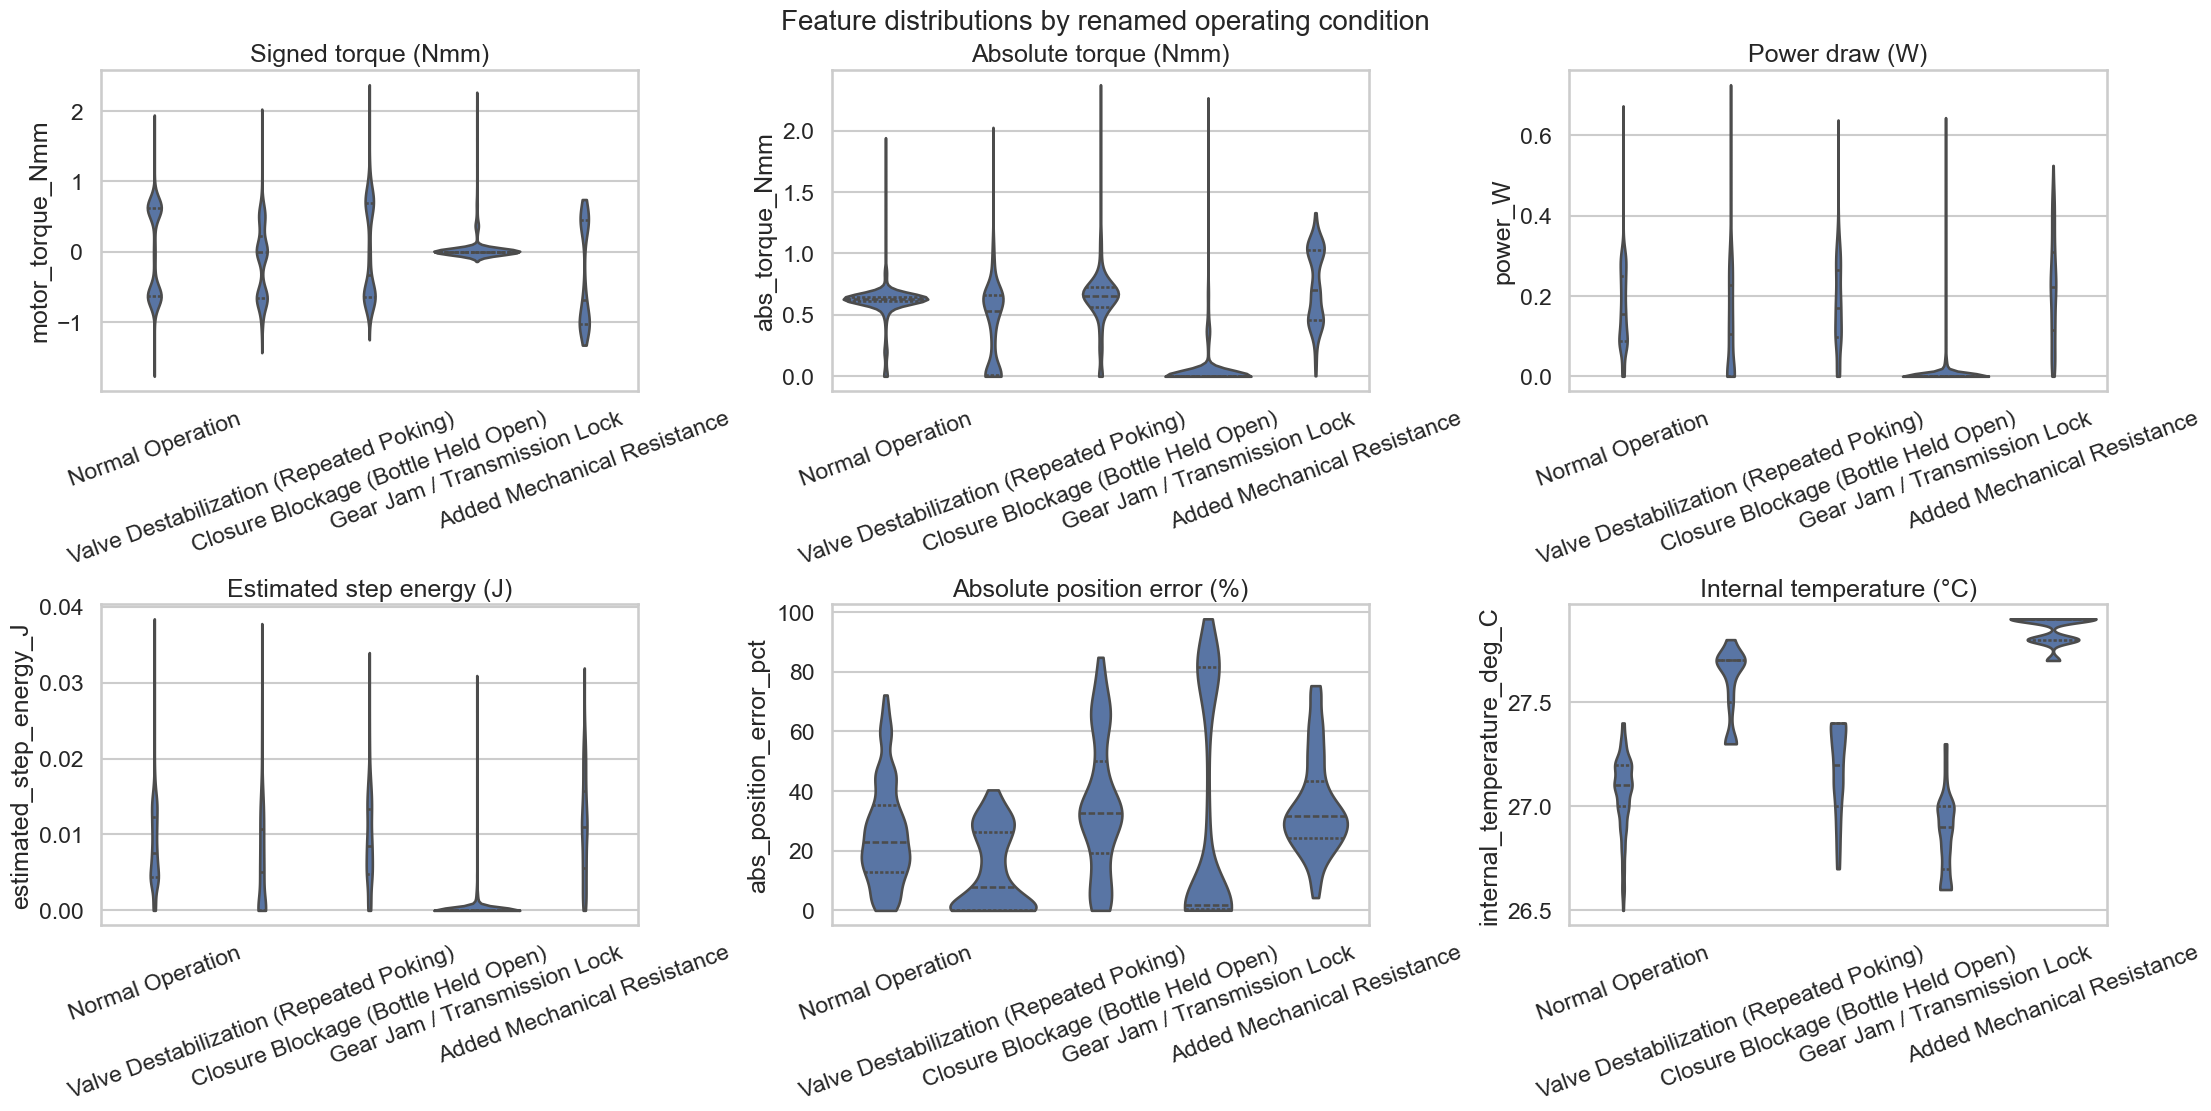

In [10]:
plot_metrics = {
    "motor_torque_Nmm": "Signed torque (Nmm)",
    "abs_torque_Nmm": "Absolute torque (Nmm)",
    "power_W": "Power draw (W)",
    "estimated_step_energy_J": "Estimated step energy (J)",
    "abs_position_error_pct": "Absolute position error (%)",
    "internal_temperature_deg_C": "Internal temperature (°C)",
}

fig, axes = plt.subplots(2, 3, figsize=(22, 11), constrained_layout=True)
for ax, (metric, title) in zip(axes.flat, plot_metrics.items()):
    sns.violinplot(
        data=df,
        x="condition_name",
        y=metric,
        order=CLASS_ORDER,
        inner="quartile",
        cut=0,
        ax=ax,
    )
    ax.set_title(title)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=20)

fig.suptitle("Feature distributions by renamed operating condition", fontsize=20)
plt.show()

## Pairwise engineering relationships

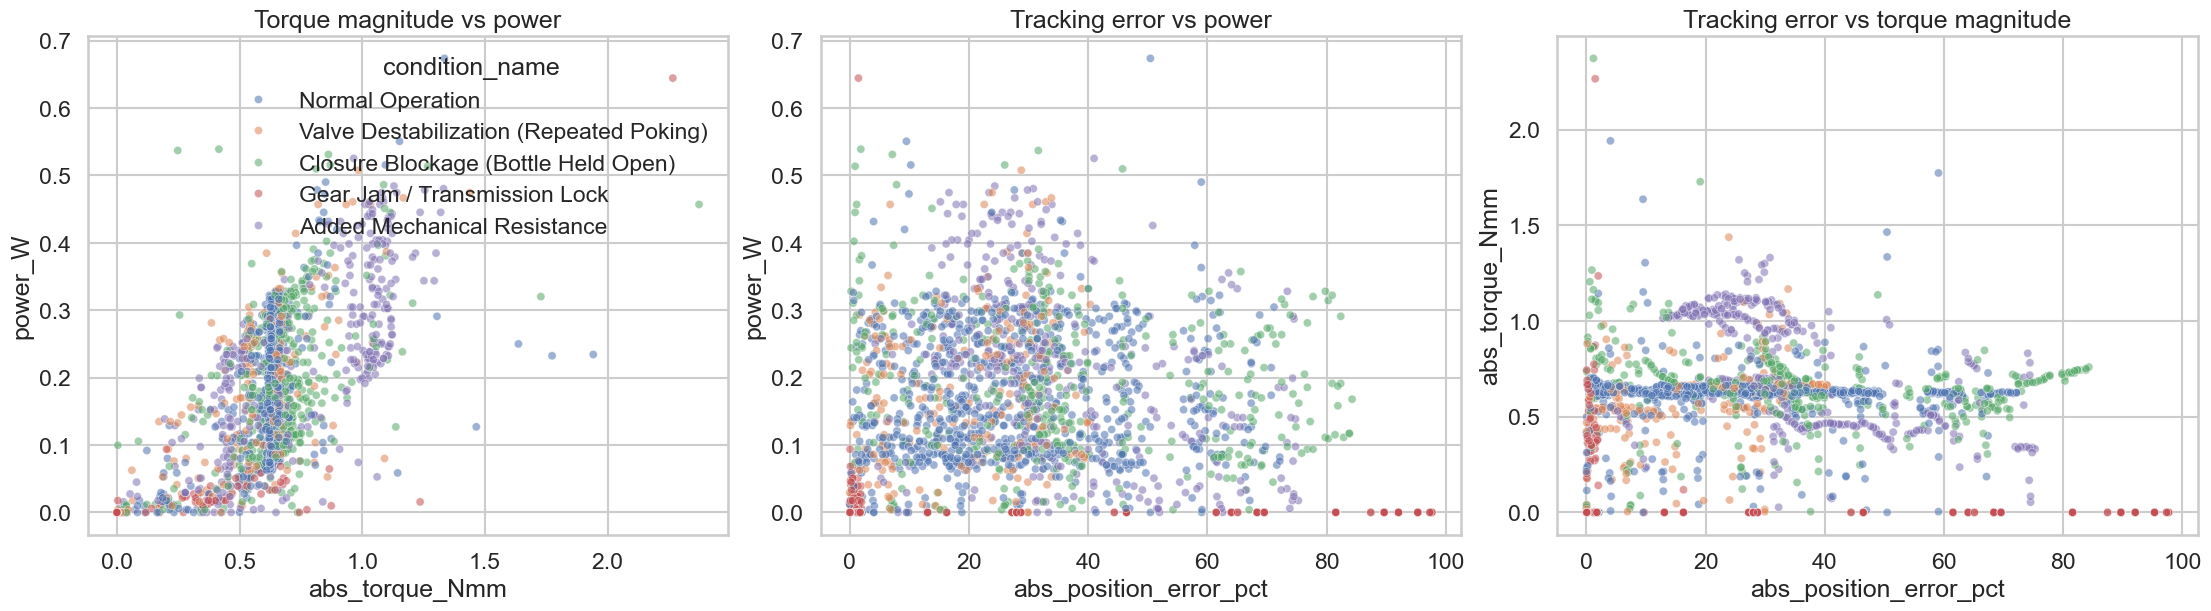

In [11]:
sample_size = min(len(df), 2500)
sampled = df.sample(sample_size, random_state=42).copy()

fig, axes = plt.subplots(1, 3, figsize=(22, 6), constrained_layout=True)

sns.scatterplot(
    data=sampled,
    x="abs_torque_Nmm",
    y="power_W",
    hue="condition_name",
    hue_order=CLASS_ORDER,
    alpha=0.55,
    s=35,
    ax=axes[0],
)
axes[0].set_title("Torque magnitude vs power")

sns.scatterplot(
    data=sampled,
    x="abs_position_error_pct",
    y="power_W",
    hue="condition_name",
    hue_order=CLASS_ORDER,
    alpha=0.55,
    s=35,
    legend=False,
    ax=axes[1],
)
axes[1].set_title("Tracking error vs power")

sns.scatterplot(
    data=sampled,
    x="abs_position_error_pct",
    y="abs_torque_Nmm",
    hue="condition_name",
    hue_order=CLASS_ORDER,
    alpha=0.55,
    s=35,
    legend=False,
    ax=axes[2],
)
axes[2].set_title("Tracking error vs torque magnitude")

plt.show()

## Representative traces per class

Each row shows one representative source file for a class. The left panel compares commanded position against measured feedback. The right panel overlays torque and power over elapsed time.

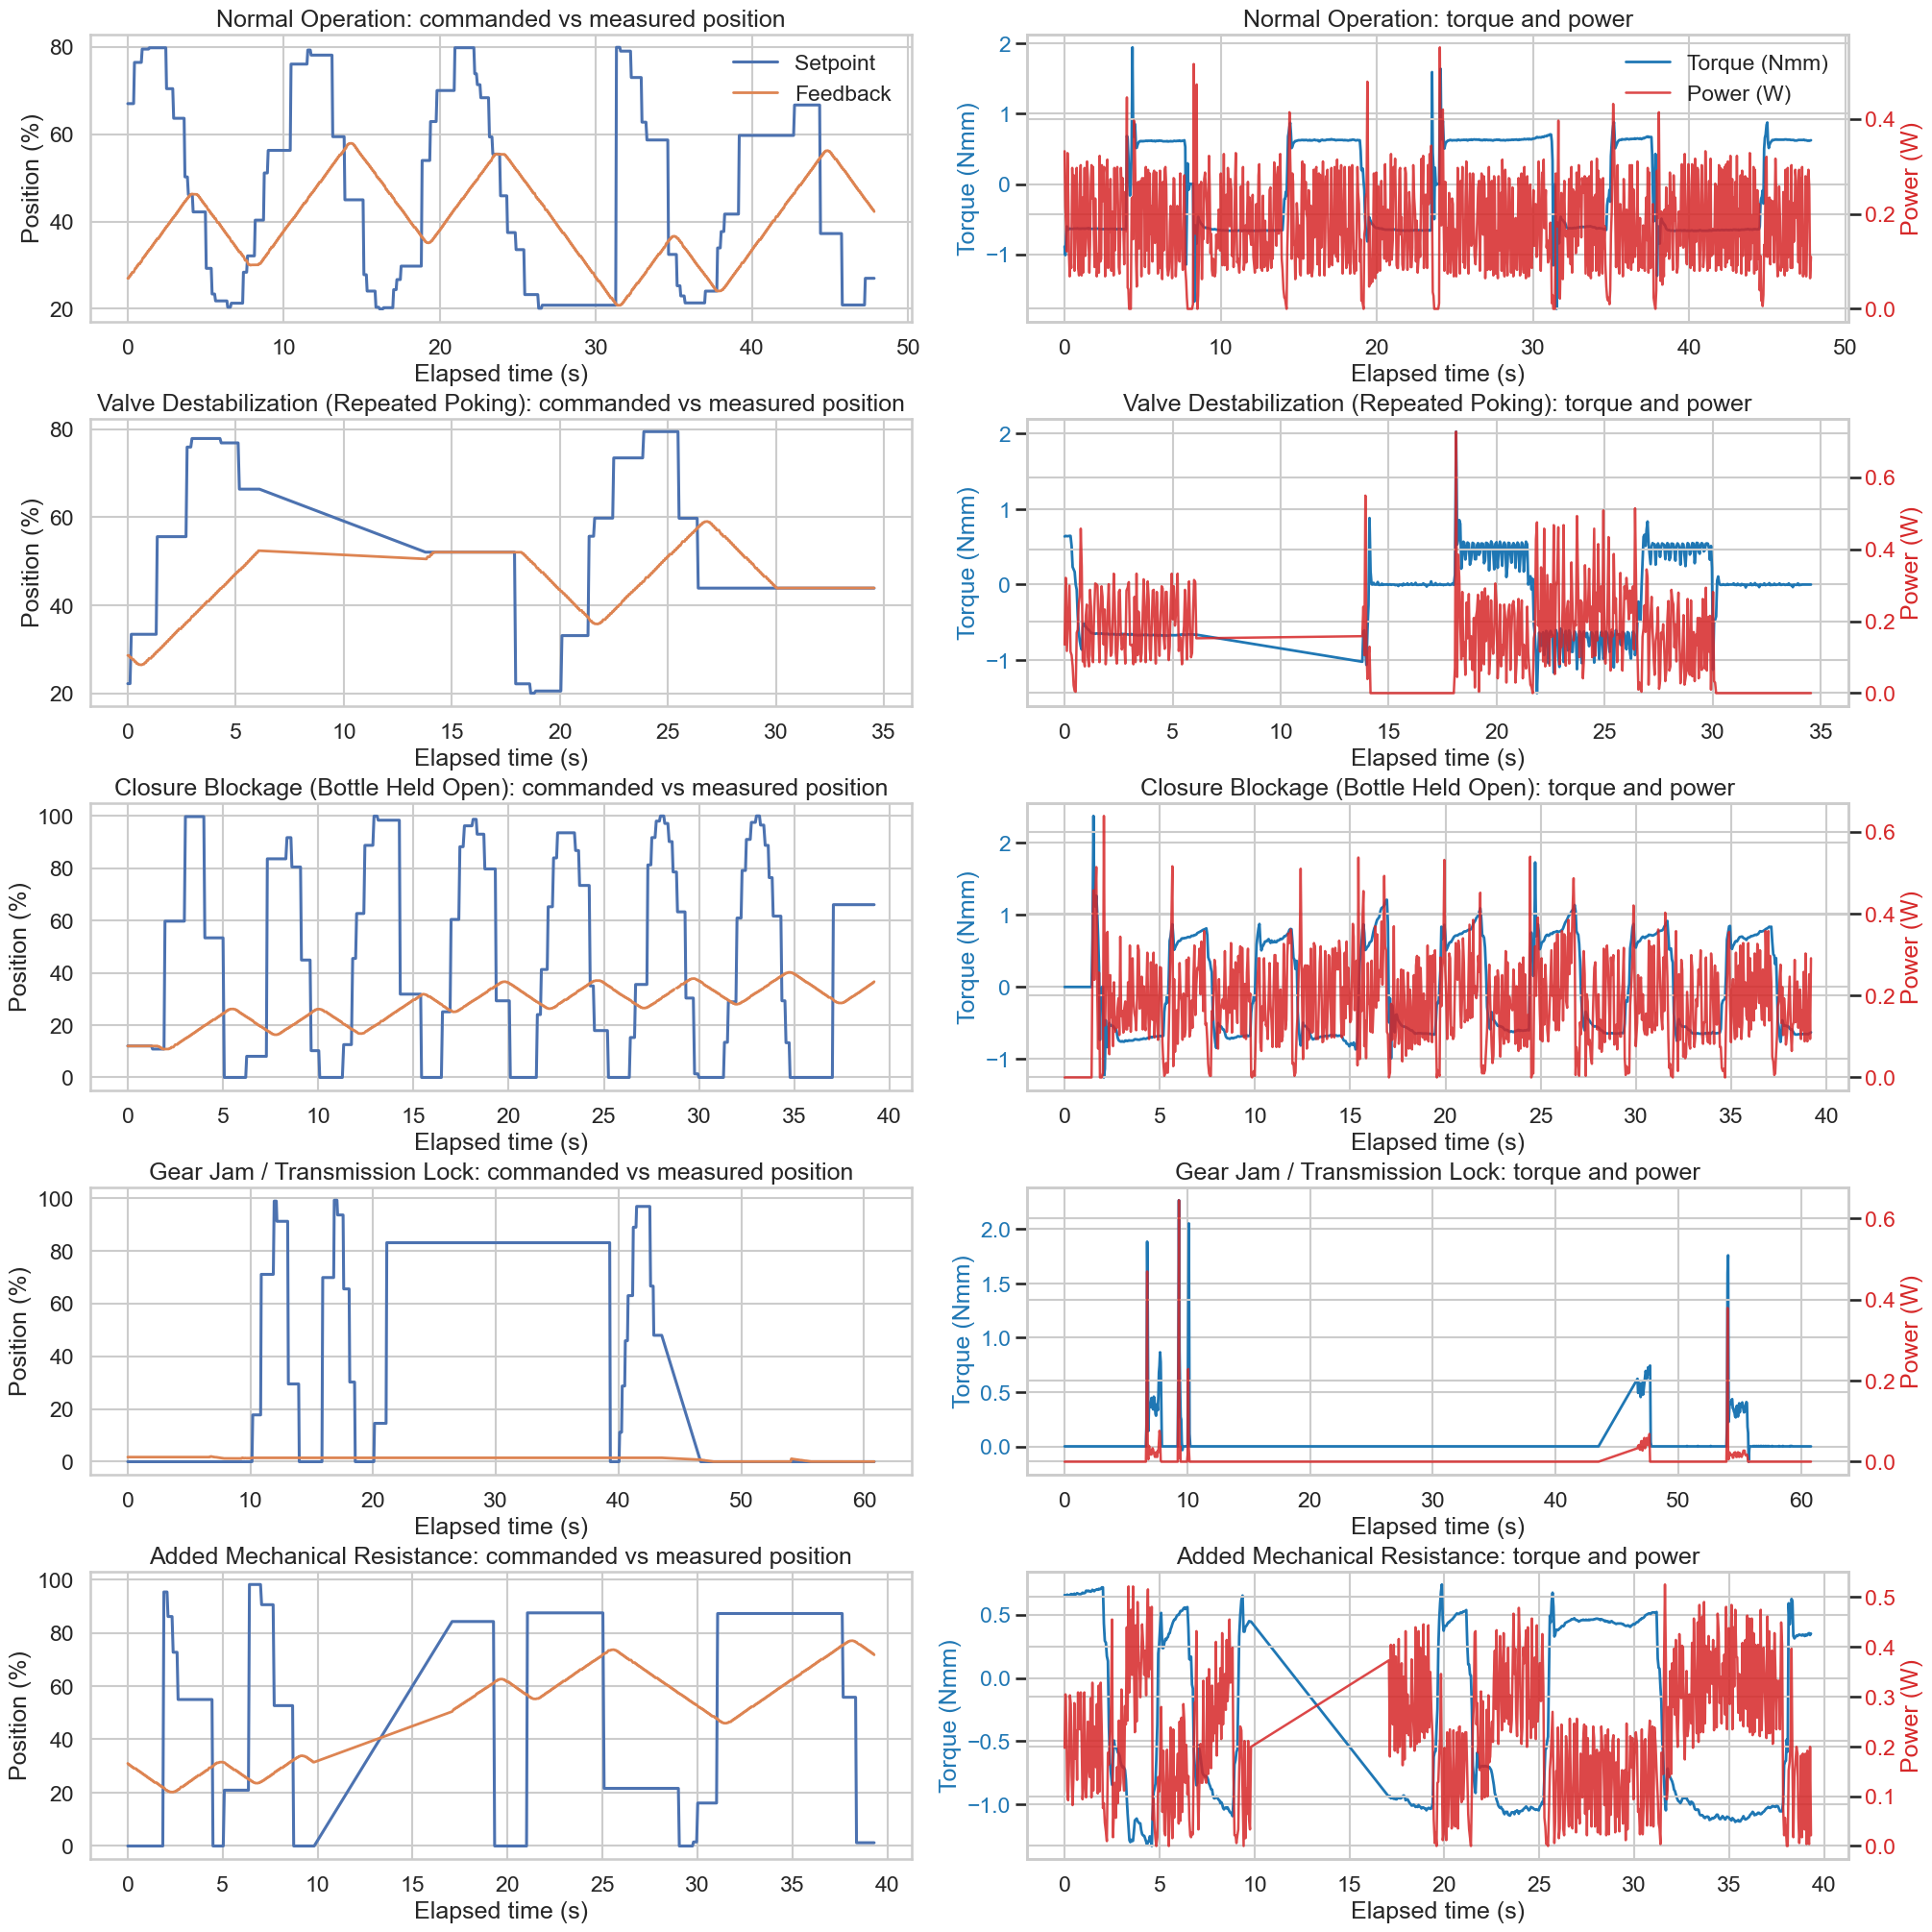

In [12]:
representative_files = (
    df.sort_values(["condition_name", "source_file", "_time"])
    .groupby("condition_name")["source_file"]
    .first()
    .reindex(CLASS_ORDER)
)

fig, axes = plt.subplots(len(CLASS_ORDER), 2, figsize=(20, 4 * len(CLASS_ORDER)), constrained_layout=True)

for row, condition_name in enumerate(CLASS_ORDER):
    source_file = representative_files.loc[condition_name]
    trace = df[df["source_file"] == source_file].sort_values("_time").copy()
    trace["elapsed_s"] = (trace["_time"] - trace["_time"].min()).dt.total_seconds()

    ax_left = axes[row, 0]
    ax_left.plot(trace["elapsed_s"], trace["setpoint_position_%"], label="Setpoint", linewidth=2.2)
    ax_left.plot(trace["elapsed_s"], trace["feedback_position_%"], label="Feedback", linewidth=2.0)
    ax_left.set_title(f"{condition_name}: commanded vs measured position")
    ax_left.set_xlabel("Elapsed time (s)")
    ax_left.set_ylabel("Position (%)")
    if row == 0:
        ax_left.legend(loc="upper right")

    ax_right = axes[row, 1]
    torque_line = ax_right.plot(trace["elapsed_s"], trace["motor_torque_Nmm"], color="tab:blue", label="Torque (Nmm)", linewidth=2.0)
    ax_right.set_xlabel("Elapsed time (s)")
    ax_right.set_ylabel("Torque (Nmm)", color="tab:blue")
    ax_right.tick_params(axis="y", labelcolor="tab:blue")
    ax_right.set_title(f"{condition_name}: torque and power")

    power_axis = ax_right.twinx()
    power_line = power_axis.plot(trace["elapsed_s"], trace["power_W"], color="tab:red", label="Power (W)", linewidth=1.8, alpha=0.85)
    power_axis.set_ylabel("Power (W)", color="tab:red")
    power_axis.tick_params(axis="y", labelcolor="tab:red")

    if row == 0:
        lines = torque_line + power_line
        labels = [line.get_label() for line in lines]
        ax_right.legend(lines, labels, loc="upper right")

plt.show()

## Quick takeaways from the current dataset

In [13]:
class_medians = (
    df.groupby("condition_name")
    .agg(
        median_error=("abs_position_error_pct", "median"),
        mean_power=("power_W", "mean"),
        mean_abs_torque=("abs_torque_Nmm", "mean"),
        mean_temp=("internal_temperature_deg_C", "mean"),
    )
    .reindex(CLASS_ORDER)
)

largest_error = class_medians["median_error"].idxmax()
highest_power = class_medians["mean_power"].idxmax()
highest_torque = class_medians["mean_abs_torque"].idxmax()
warmest = class_medians["mean_temp"].idxmax()
lowest_power = class_medians["mean_power"].idxmin()

print(f"Largest median tracking error: {largest_error} ({class_medians.loc[largest_error, 'median_error']:.2f}%).")
print(f"Highest mean power draw: {highest_power} ({class_medians.loc[highest_power, 'mean_power']:.3f} W).")
print(f"Highest mean torque magnitude: {highest_torque} ({class_medians.loc[highest_torque, 'mean_abs_torque']:.3f} Nmm).")
print(f"Warmest operating condition: {warmest} ({class_medians.loc[warmest, 'mean_temp']:.2f} °C).")
print(f"Lowest mean power draw: {lowest_power} ({class_medians.loc[lowest_power, 'mean_power']:.3f} W).")

Largest median tracking error: Closure Blockage (Bottle Held Open) (32.66%).
Highest mean power draw: Added Mechanical Resistance (0.221 W).
Highest mean torque magnitude: Added Mechanical Resistance (0.739 Nmm).
Warmest operating condition: Added Mechanical Resistance (27.85 °C).
Lowest mean power draw: Gear Jam / Transmission Lock (0.004 W).
